In [8]:
import seaborn as sns
import pandas as pd

# Ambil dataset Titanic asli
df = sns.load_dataset('titanic')

# Cek struktur datanya
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [9]:
import pandas as pd

# 1. Isi missing values
df['age'] = df['age'].fillna(df['age'].median())  # Isi umur kosong dengan nilai median
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])  # Isi embarked kosong dengan nilai terbanyak

# 2. Hapus kolom yang tidak dipakai / duplikat
# 'deck' dibuang karena mayoritas kosong, Sisanya duplikat ('class' = 'pclass', 'alive' = 'survived', dll)
df = df.drop(columns=['deck', 'embark_town', 'alive', 'class', 'who', 'adult_male', 'alone'])

# 3. Ubah kolom teks (kategorikal) menjadi angka
# Transformasi 'sex' (female -> 0, male -> 1)
df['sex'] = df['sex'].map({'female': 0, 'male': 1})

# One-Hot Encoding untuk 'embarked' (S, C, Q)
df = pd.get_dummies(df, columns=['embarked'], drop_first=True)

# Tampilkan data hasil preprocessing
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S
0,0,3,1,22.0,1,0,7.2500,False,True
1,1,1,0,38.0,1,0,71.2833,False,False
2,1,3,0,26.0,0,0,7.9250,False,True
3,1,1,0,35.0,1,0,53.1000,False,True
4,0,3,1,35.0,0,0,8.0500,False,True


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Pemisahan Fitur (X) dan Target (y)
X = df.drop(columns=['survived'])  # Semua kolom kecuali 'survived'
y = df['survived']                 # Target yang mau diprediksi (0/1)

# 2. Split data: 80% data latih (train), 20% data uji (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scaling fitur numerik (disarankan agar skala angka seimbang)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Inisialisasi ketiga algoritma
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# 5. Training dan evaluasi tiap model
print("=== AKURASI MODEL PREDIKSI TITANIC ===\n")
for name, model in models.items():
    # Latih model
    model.fit(X_train_scaled, y_train)

    # Prediksi data uji
    y_pred = model.predict(X_test_scaled)

    # Hitung akurasi
    acc = accuracy_score(y_test, y_pred)
    print(f"{name}: {acc * 100:.2f}%")

=== AKURASI MODEL PREDIKSI TITANIC ===

Logistic Regression: 81.01%
Decision Tree: 78.77%
Random Forest: 81.01%


In [11]:
# Evaluasi detail Random Forest
rf_model = models["Random Forest"]
y_pred_rf = rf_model.predict(X_test_scaled)

print("=== CLASSIFICATION REPORT (RANDOM FOREST) ===")
print(classification_report(y_test, y_pred_rf))

=== CLASSIFICATION REPORT (RANDOM FOREST) ===
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



=== FITUR PALING BERPENGARUH ===
fare          0.279199
sex           0.266967
age           0.249413
pclass        0.081051
sibsp         0.053500
parch         0.035840
embarked_S    0.024301
embarked_Q    0.009729
dtype: float64


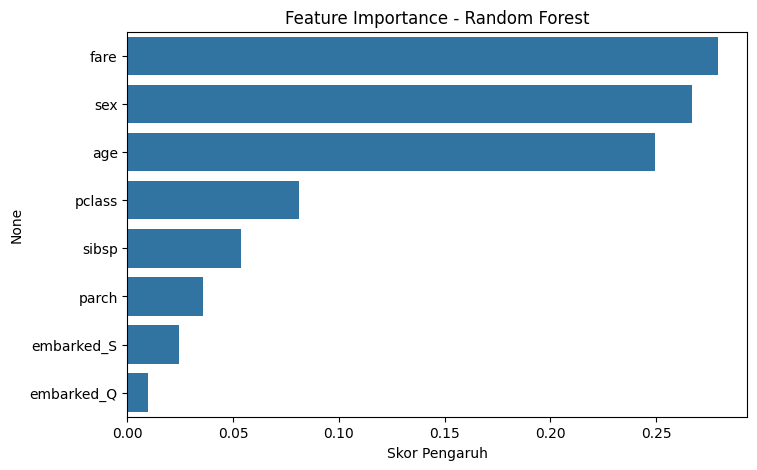

In [14]:
import matplotlib.pyplot as plt

# Cek fitur paling berpengaruh di Random Forest
importance = pd.Series(rf_model.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)

print("=== FITUR PALING BERPENGARUH ===")
print(importance)

# Visualisasi dengan barplot
plt.figure(figsize=(8, 5))
sns.barplot(x=importance, y=importance.index)
plt.title("Feature Importance - Random Forest")
plt.xlabel("Skor Pengaruh")
plt.show()